# Assignment 8 — Diabetes Prediction Using SVM & Naive Bayes
# 9. Assignment

**Dataset:** [Diabetes Prediction Dataset – Kaggle](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset)

**Description:** The dataset contains ~100,000 patient records with 8 medical & demographic features and a binary target (`diabetes`: 0 or 1).

**Features:** `gender`, `age`, `hypertension`, `heart_disease`, `smoking_history`, `bmi`, `HbA1c_level`, `blood_glucose_level`

---

### Tasks:
1. Download the dataset from Kaggle and upload it to your Google Drive.
2. Load & preprocess the data (handle categoricals, scale features).
3. Train **SVM** and **Naive Bayes** classifiers.
4. Evaluate using **Precision, Recall, F1-Score, and ROC-AUC Curve**.
5. Create a **Results Summary Table** comparing both models.



## 1. Setup & Imports

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score)
import warnings
warnings.filterwarnings('ignore')
RANDOM_STATE = 42

## 2. Load & Inspect Dataset
Upload `diabetes_prediction_dataset.csv` to Google Drive under `MyDrive/datasets/` when using Colab. The notebook also supports the CSV beside the notebook.

In [65]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [66]:
local_path = Path('diabetes_prediction_dataset.csv')
if local_path.exists():
    data_path = local_path
else:
    from google.colab import drive
    drive.mount('/content/drive')
    data_path = Path('/content/drive/MyDrive/skill_morph/datasets/diabetes_prediction_dataset.csv')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [67]:
df = pd.read_csv(data_path)
print('Dataset shape:', df.shape)

Dataset shape: (100000, 9)


In [68]:
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [69]:
print('\nMissing values:\n', df.isna().sum())
print('\nTarget distribution:\n', df['diabetes'].value_counts())


Missing values:
 gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Target distribution:
 diabetes
0    91500
1     8500
Name: count, dtype: int64


In [70]:
# Check duplicate records
print("Original dataset shape:", df.shape)

duplicate_count = df.duplicated().sum()
print("Duplicate records:", duplicate_count)

print("Duplicate percentage:",
      round(duplicate_count / len(df) * 100, 2), "%")

# Remove exact duplicates
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

# Check class distribution
print("\nClass Distribution:")
print(df['diabetes'].value_counts())

Original dataset shape: (100000, 9)
Duplicate records: 3854
Duplicate percentage: 3.85 %
Dataset shape after removing duplicates: (96146, 9)

Class Distribution:
diabetes
0    87664
1     8482
Name: count, dtype: int64


## 3. Exploratory Data Analysis

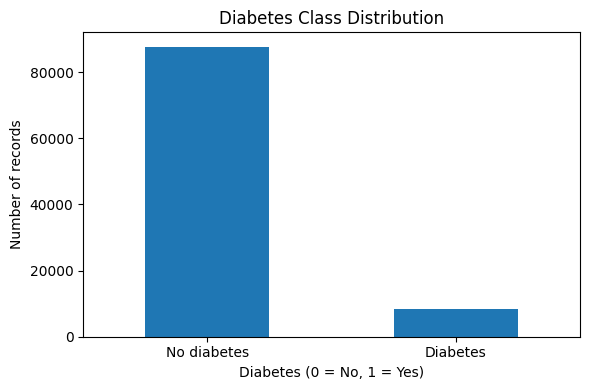

In [71]:
fig, ax = plt.subplots(figsize=(6, 4))
df['diabetes'].value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set_title('Diabetes Class Distribution')
ax.set_xlabel('Diabetes (0 = No, 1 = Yes)')
ax.set_ylabel('Number of records')
ax.set_xticklabels(['No diabetes', 'Diabetes'], rotation=0)
plt.tight_layout()
plt.show()

## 4. Preprocessing & Stratified Train-Test Split
Categorical features are one-hot encoded, numeric features are median-imputed and standardized. The preprocessing is fitted **only on training data** to prevent data leakage. An 80/20 stratified split retains the class proportions.

In [72]:
X = df.drop(columns=['diabetes'])
y = df['diabetes']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

In [73]:
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = X.columns.difference(categorical_cols).tolist()

In [74]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_transformer, numeric_cols),
    ('categorical', categorical_transformer, categorical_cols)
])

In [75]:
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)
print('Train:', X_train_scaled.shape, '| Test:', X_test_scaled.shape)

Train: (76916, 15) | Test: (19230, 15)


## 5. Model Training — SVM & Naive Bayes

In [76]:
# Reproducible, class-stratified SVM training subset (20,000 rows)
svm_train_size = min(20000, len(y_train))
if svm_train_size < len(y_train):
    svm_indices, _ = train_test_split(
        np.arange(len(y_train)), train_size=svm_train_size,
        stratify=y_train, random_state=RANDOM_STATE
    )
else:
    svm_indices = np.arange(len(y_train))

In [77]:
# SVM (RBF kerner with probability estimates for ROC)
svm_model = SVC(kernel='rbf', probability=False, random_state=RANDOM_STATE)
svm_model.fit(X_train_scaled[svm_indices], y_train.iloc[svm_indices])
y_pred_svm = svm_model.predict(X_test_scaled)
y_score_svm = svm_model.decision_function(X_test_scaled)

# Gaussian NB
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
y_pred_nb = nb_model.predict(X_test_scaled)
y_score_nb = nb_model.predict_proba(X_test_scaled)[:, 1]
print(f'SVM trained on {len(svm_indices):,} records; Naive Bayes trained on {len(y_train):,} records.')

SVM trained on 20,000 records; Naive Bayes trained on 76,916 records.


## 6. Evaluation — Classification Reports & Confusion Matrices

In [78]:
print('=' * 55, '\nSVM Classification Report\n', '=' * 55)
print(classification_report(y_test, y_pred_svm, target_names=['No diabetes', 'Diabetes'], digits=4, zero_division=0))

print('=' * 55, '\nNaive Bayes Classification Report\n', '=' * 55)
print(classification_report(y_test, y_pred_nb, target_names=['No diabetes', 'Diabetes'], digits=4, zero_division=0))

SVM Classification Report
              precision    recall  f1-score   support

 No diabetes     0.9625    0.9970    0.9794     17534
    Diabetes     0.9503    0.5979    0.7340      1696

    accuracy                         0.9618     19230
   macro avg     0.9564    0.7974    0.8567     19230
weighted avg     0.9614    0.9618    0.9578     19230

Naive Bayes Classification Report
              precision    recall  f1-score   support

 No diabetes     0.9938    0.5900    0.7404     17534
    Diabetes     0.1849    0.9617    0.3102      1696

    accuracy                         0.6228     19230
   macro avg     0.5893    0.7758    0.5253     19230
weighted avg     0.9224    0.6228    0.7025     19230



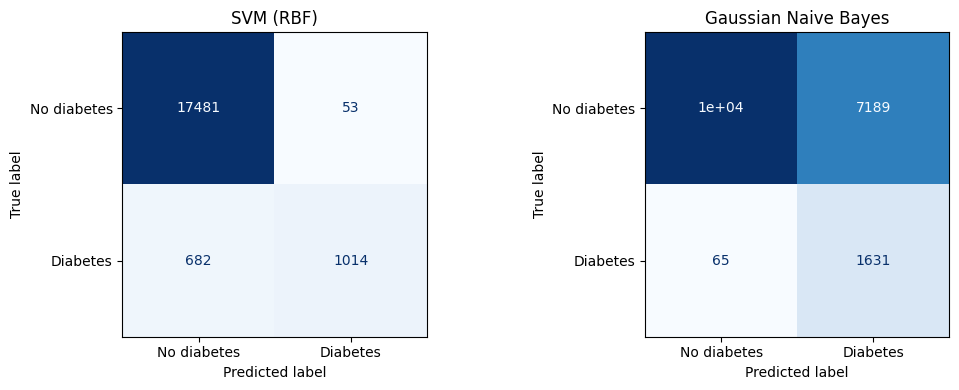

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, name in zip(axes, [y_pred_svm, y_pred_nb], ['SVM (RBF)', 'Gaussian Naive Bayes']):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=['No diabetes', 'Diabetes']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 7. ROC-AUC Curve Comparison
SVM uses its decision-function scores, and Naive Bayes uses predicted probabilities. Both are valid inputs for ROC-AUC.

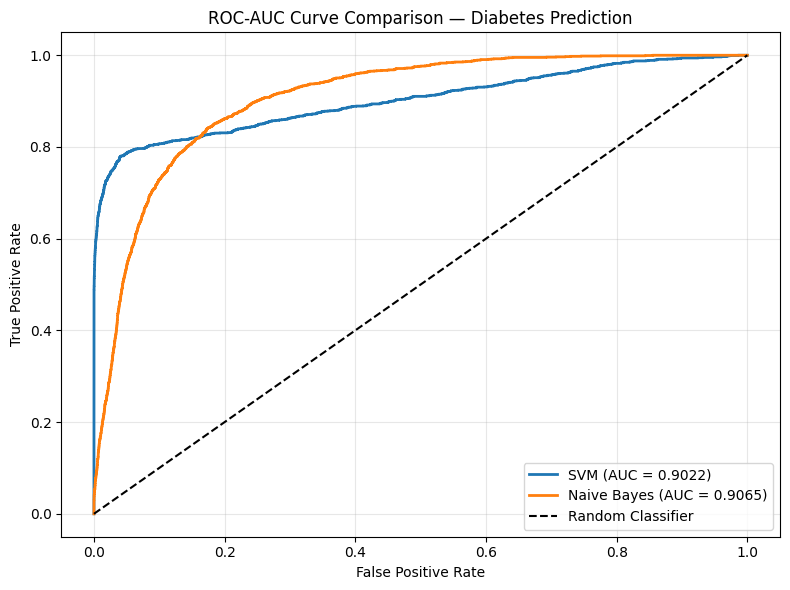

In [80]:
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_score_svm)
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_score_nb)
auc_svm = roc_auc_score(y_test, y_score_svm)
auc_nb = roc_auc_score(y_test, y_score_nb)

plt.figure(figsize=(8, 6))
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {auc_svm:.4f})', linewidth=2)
plt.plot(fpr_nb, tpr_nb, label=f'Naive Bayes (AUC = {auc_nb:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve Comparison — Diabetes Prediction')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('assignment8_roc_auc_curve.png', dpi=600)
plt.show()

## 8. Results Summary Table
Precision, recall, and F1 below use the **diabetes-positive class (1)**, which is particularly relevant given the class imbalance.

In [81]:
results = pd.DataFrame([
    {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-Score': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, score)
    }
    for name, pred, score in [
        ('SVM (RBF)', y_pred_svm, y_score_svm),
        ('Naive Bayes', y_pred_nb, y_score_nb)
    ]
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,SVM (RBF),0.9618,0.9503,0.5979,0.7340,0.9022
1,Naive Bayes,0.6228,0.1849,0.9617,0.3102,0.9065
